# Modelagem Preditiva e Scorecard de Crédito

Nesse notebook, daremos vida aos modelos de Machine Learning capazes de prever a probabilidade de inadimplência (`SeriousDlqin2yrs`). 

O fluxo será estruturado nas seguintes etapas:
- **Preparação dos Dados:** Carga da base tratada do SQLite, conversão de variáveis categóricas, divisão em Treino/Teste (evitando *data-leakage*) e preservação estratégica dos valores ausentes (`NaN`) nas colunas de histórico de atraso para exploração nativa por algoritmos de *Gradient Boosting*.

- **Baseline (Regressão Logística / Scorecard Tradicional):** O padrão da indústria bancária que permite traduzir coeficientes estatísticos em uma pontuação de crédito interpretável. 

- **XGBoost:** Capturando não-linearidades complexas e interações profundas para maximizar a performance preditiva da carteira.

- **Avaliação Especializada em Risco:** Uso rigoroso da **ROC-AUC** e da **Estatística KS (Kolmogorov-Smirnov)** para medir a capacidade real de discriminação e separação entre bons e maus pagadores.

- **Interpretabilidade e Políticas de Crédito:** Análise de *Feature Importance* para auditoria das decisões do modelo, definição de *cut-offs* comerciais (Zonas Verde, Amarela e Vermelha) alinhados ao apetite de risco e serialização dos artefatos para produção.

In [24]:
## Setup e Carga da Base Processada

# Importações essenciais para modelagem e métricas
import sqlite3 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from xgboost import XGBClassifier

# Configuração visual e de exibição 
pd.set_option('display.max_columns', None)
import warnings
warnings.filterwarnings('ignore')

print("Carregando a base tratada do SQLite...")

# Carregando a base enriquecida do banco de dados SQLite
conexao = sqlite3.connect("../data/credit_scoring.db")
df_modelagem = pd.read_sql("SELECT * FROM credito_feature_engineered", conexao)
conexao.close()

print(f"Base Carregada com Sucesso! \nDimensões: {df_modelagem.shape}")

Carregando a base tratada do SQLite...
Base Carregada com Sucesso! 
Dimensões: (149999, 18)


## Preparação dos Dados para a Modelagem e Divisão Treino/Teste

Antes de treinar os algoritmos, precisamos preparar o notebook:

* **Tratamento da Variável Categórica (`Faixa_Utilizacao`):** Como os modelos só entendem números, transformaremos a faixa de utilização em colunas binárias numéricas utilizando o One-Hot Encoding (`pd.get_dummies`).

* **Separação de Variáveis Preditoras (`X`) e Alvo (`y`):** Definimos que o objetivo (`y`) é prever a coluna `SeriousDlqin2yrs`, enquanto o restante da base limpa enriquecida formará as features descritivas (`X`).

* **Divisão Estratificada (Stratified Train-Test Split):** Como vimos que a base é altamente desbalanceada (~6,7% de maus pagadores), é obrigatório usar a estratificação (`stratify=y`) na divisão entre treino e teste, garantindo que tanto o conjunto de treino quanto o de teste mantenham exatamente a mesma proporção de bons e maus pagadores, evitando que o modelo treine com um viés incorreto. 

In [25]:
## Encoding e Divisão de Dados

# Tratando a variável categórica 'Faixa_Utilizacao' com One-Hot 
# drop_first=True evita a armadilha de colinearidade (multicolinearidade perfeita) em modelos lineares
df_modelagem = pd.get_dummies(df_modelagem, columns=['Faixa_Utilizacao'], drop_first=True, dtype=int)
print("Colunas após o One-Hot Encoding:")
print(df_modelagem.columns.tolist())

# Separando X (features) e y (target)
X = df_modelagem.drop(columns=['SeriousDlqin2yrs'])
y = df_modelagem['SeriousDlqin2yrs']

# Divisão em Treino (80%) e Teste (20%) com estratificação 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nDimensões dos conjuntos criados:")
print(f"X_train (Treino features): {X_train.shape}")
print(f"X_test (Teste features): {X_test.shape}")

print(f"\nProporção de Inadimplentes (Target = 1) no Treino e no Teste:")
print(f"Treino: {y_train.mean() * 100:.2f}%")
print(f"Teste: {y_test.mean() * 100:.2f}%")

Colunas após o One-Hot Encoding:
['SeriousDlqin2yrs', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'Renda_Ausente_Flag', 'RevolvingUtilizationOfUnsecuredLines_clipped', 'DebtRatio_clipped', 'Total_Atrasos', 'Historico_Atrasos_Flag', 'Renda_Por_Dependente', 'Proporcao_Imobiliaria', 'Utilizacao_Critica_Flag', 'Faixa_Utilizacao_Baixa (0-30%)', 'Faixa_Utilizacao_Estourado (>100%)', 'Faixa_Utilizacao_Moderada (30-70%)', 'Faixa_Utilizacao_Sem Utilização (0%)']

Dimensões dos conjuntos criados:
X_train (Treino features): (119999, 20)
X_test (Teste features): (30000, 20)

Proporção de Inadimplentes (Target = 1) no Treino e no Teste:
Treino: 6.68%
Teste: 6.68%


**One-Hot Encoding Concluído:** A variável categórica `Faixa_Utilizacao` foi convertida em colunas binárias numéricas (com `drop_first=True` evitando colinearidade), elevando o total de features preditoras para 20 variáveis.

**Estratificação:** A divisão de 80% para treino e 20% para teste preservou a taxa de inadimplência de 6,68% em ambos os blocos.

---
Com a base blindada e dividida, podemos treinar o modelo Baseline (Regressão Logística), que servirá como a base tradicional de scorecard. 

## Baseline - Regressão Logística (O Scorecard Tradicional do Mercado)

No setor bancário, a Regressão Logística é o padrão regulatório e de mercado para a construção de *Scorecards* de crédito. 
Diferente dos modelos "caixa-preta", a Regressão Logística gera coeficientes claros para cada variável. Esses coeficientes podem ser diretamente traduzidos em uma pontuação de crédito (ex: score de 300 a 850), permitindo que o analista de crédito explique exatamente o porquê de um cliente ter sido aprovado ou negado. 

* **Cuidados Técnicos:** Como a Regressão Logística penaliza a magnitude dos coeficientes, é obrigatório padronizar as features numéricas (`StandardScaler`) para que variáveis com escalas gigantescas não dominem o modelo injustamente em relação a variáveis binárias (0 ou 1). Além disso, como os modelos lineares exigem dados completos, inserimos um imputador estatístico no pipeline para tratar os `NaN` das colunas de atraso preservados para as árvores.

In [26]:
## Treinando e Avaliando o Baseline

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Criando um Pipeline que trata os NaNs (com mediana), padroniza os dados e aplica a Regressão Logística 
pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

print("Treinando o Baseline (Regressão Logística)")
pipeline_lr.fit(X_train, y_train)

# Obtendo as probabilidades preditas para a classe 1 (inadimplentes) no conjunto de teste
y_pred_proba_lr = pipeline_lr.predict_proba(X_test)[:, 1]

# Calculando a métrica ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_pred_proba_lr)
print(f"ROC-AUC do Baseline (Regressão Logística): {roc_auc_lr:.4f}")

# Relatório de classificação preliminar (usando limiar padrão de 0.5)
y_pred_lr = pipeline_lr.predict(X_test)
print("\nRelatório de Classificação (Threshold = 0.5):")
print(classification_report(y_test, y_pred_lr))

Treinando o Baseline (Regressão Logística)
ROC-AUC do Baseline (Regressão Logística): 0.8624

Relatório de Classificação (Threshold = 0.5):
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     27995
           1       0.22      0.76      0.34      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.78      0.61     30000
weighted avg       0.93      0.80      0.85     30000



**Poder Discriminatório Sólido:** No mercado de crédito, um ROC-AUC acima de 0.80 já é considerado um modelo de bom desempenho. A marca de 0.8624 comprova que as variáveis criadas capturaram o comportamento de risco da carteira. 

**O Equilíbrio do Recall:** Utilizando o parâmetro `class_weight='balanced'`, o modelo conseguiu resgatar 76% de todos os maus pagadores da base de teste. Isso é vital para a instituição financeira, pois evita que clientes de alto risco passem despercebidos. 

**O Desafio da Precisão no Limiar Padrão:** Como o limiar (*threshold*) foi fixo em 0.5, geraram falsos positivos (bons pagadores classificados como de risco), o que derruba a precisão para 22%. 

---
A próxima etapa será treinar o XGBoost, um algoritmo baseado em árvore que consegue capturar não-linearidades complexas e interações profundas entre as variáveis para tentar superar o modelo baseline. 

## XGBoost (*Extreme Gradiente Boosting*)

Enquanto a Regressão Logística busca uma linha reta de separação (relação linear), o XGBoost constrói árvores de decisão em sequência, onde cada árvore nova foca nos erros (resíduos) cometidos pelas anteriores. Esse modelo é excelente para capturar não-linearidades e interações complexas entre variáveis (ex: um cliente jovem com utilização alta **e** histórico de atraso pode ter um risco exponencialmente maior do que a soma desses fatores isolados).

* **Tratamento do Desbalanceamento:** Para garantir que o XGBoost não ignore a classe minoritária de maus pagadores (6,68%), será utilizado o parâmetro **`scale_pos_weight`**, que penaliza severamente os erros cometidos na classe de inadimplentes, equilibrando a balança de aprendizado. 

In [27]:
## Treinando e Avaliando o XGBoost

from xgboost import XGBClassifier

# Calculando o scale_pos_weight para lidar com o desbalanceamento de classes
#  Razão entre o número de clientes bons (0) e maus (1) no treino
negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()
scale_pos_weight_val = negativos / positivos

print(f"Razão Calculada para scale_por_weight: {scale_pos_weight_val:.2f}")

# Instanciando o modelo XGBoost com hiperparâmetros robustos
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    eval_metrics='auc',
    n_jobs=-1
)

print("Treinando o XGBoost")
xgb_model.fit(X_train, y_train)

# Obtendo as probabilidades preditas para a classe 1 no conjunto de teste
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calculando a métrica ROC-AUC do XGBoost
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
print(f"\nROC-AUC do XGBoost: {roc_auc_xgb:.4f}")
print(f"ROC-AUC anterior do modelo Baseline (Regressão Logística): {roc_auc_lr:.4f}")

# Relatório de classificação preliminar
y_pred_xgb = xgb_model.predict(X_test)
print("\nRelatório de Classificação do XGBoost (Threshold = 0.5):")
print(classification_report(y_test, y_pred_xgb))

Razão Calculada para scale_por_weight: 13.96
Treinando o XGBoost

ROC-AUC do XGBoost: 0.8694
ROC-AUC anterior do modelo Baseline (Regressão Logística): 0.8624

Relatório de Classificação do XGBoost (Threshold = 0.5):
              precision    recall  f1-score   support

           0       0.98      0.81      0.88     27995
           1       0.22      0.78      0.35      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.79      0.61     30000
weighted avg       0.93      0.80      0.85     30000



**Superação do modelo Baseline (ROC-AUC 0.8694):** O XGBoost superou os 0.8624 da Regressão Logística, provando que a carteira de crédito possui padrões não-lineares e interações complexas (ex: a combinação de alta utilização de limite com histórico de atraso) que árvores de decisão capturam.

**Ganho de Sensibilidade (Recall 0.78):** O modelo conseguiu identificar 78% de todos os inadimplentes da base de teste, garantindo uma proteção robusta para a carteira da instituição financeira contra calotes imprevistos.

Com uma perfomance superior tanto em AUC quanto em Recall, o XGBoost demonstra ser a melhor escolha preditiva para a API de score, enquanto a Regressão Logística do modelo baseline permanece como a referência regulatória de interpretabilidade. 

## Métrica de Risco: Estatística KS 

Enquanto o ROC-AUC avalia a capacidade geral de ordenação do modelo, a KS calcula a distância máxima vertical entre a curva cumulativa de bons pagadores e a curva cumulativa de maus pagadores ao longo de todas as probabilidades preditas. Ou seja, quanto maior o valor da KS (geralmente expresso em porcentagem), melhor é o modelo em separar quem vai pagar de quem vai dar calote no ponto de corte mais crítico da operação. Valores KS acima de 40% indicam excelente poder preditivo em risco de crédito.

Estatística KS do Baseline (Regressão Logística): 57.16%
Estatística KS do XGBoost: 58.36%


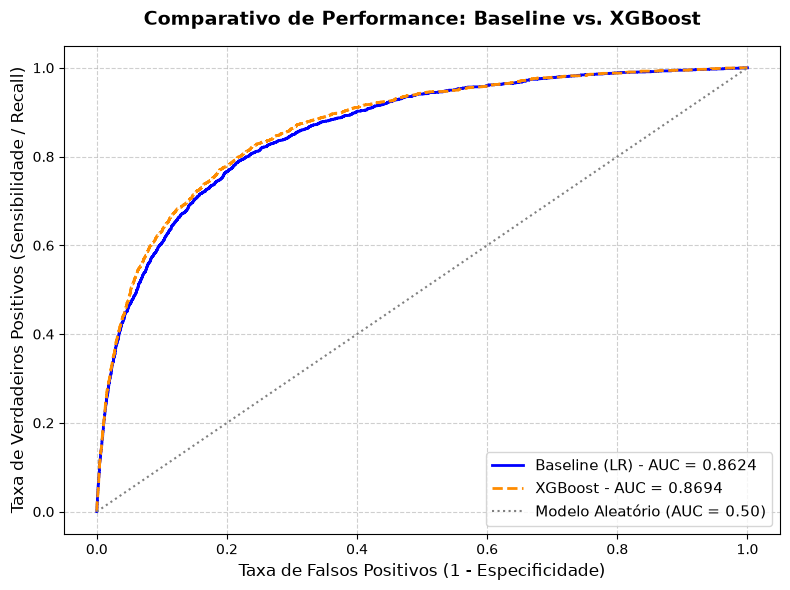

In [28]:
## Calculando a Estatística KS e Plotando as Curvas ROC

from scipy.stats import ks_2samp
from sklearn.metrics import roc_curve

# Função para calcular Estatística KS
def calcular_estatistica_ks(y_true, y_proba):
    # Cria um DataFrame auxiliar com a target e as probabilidades preditas
    df_temp = pd.DataFrame({'y_true': y_true, 'proba': y_proba})

    # Separa as probabilidades dos bons pagadores (0) e dos maus pagadores (1)
    bons = df_temp[df_temp['y_true'] == 0]['proba']
    maus = df_temp[df_temp['y_true'] == 1]['proba']
    
    resultado = ks_2samp(bons, maus) # type: ignore
    return float(resultado[0]) # type: ignore 

# Calculando o KS para os dois modelos
ks_lr = calcular_estatistica_ks(y_test, y_pred_proba_lr)
ks_xgb = calcular_estatistica_ks(y_test, y_pred_proba_xgb)

print(f"Estatística KS do Baseline (Regressão Logística): {ks_lr * 100:.2f}%")
print(f"Estatística KS do XGBoost: {ks_xgb * 100:.2f}%")

# Plotando a Curca ROC comparativa 
plt.figure(figsize=(8, 6))

# Curva ROC Regrssão Logística
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Baseline (LR) - AUC = {roc_auc_lr:.4f}', color='blue', linewidth=2)

# Curva ROC XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost - AUC = {roc_auc_xgb:.4f}', color='darkorange', linewidth=2, linestyle='--')

# Linha de referência aleatória (50%)
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Modelo Aleatório (AUC = 0.50)')

plt.title('Comparativo de Performance: Baseline vs. XGBoost', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Salvando a imagem 
import os 
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "comparativo_performance_baseline_xgboost.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

**Poder Discriminatório:** No mercado de crédito, um índice KS acima de 40% já classifica o modelo como excelente. A marca de 58,36% alcançada pelo XGBoost (superando os 57,16% da Regressão Logística) comprova que o modelo possui altíssima capacidade de separação dos bons e maus pagadores no ponto crítico de decisão.

O ganho tanto em ROC-AUC (0.8694) quanto em Estatística KS valida matematicamente a escolha do XGBoost como modelo de predição de risco.

## Interpretabilidade do Modelo Campeão (XGBoost): Feature Importance

Em risco de crédito e em comitês regulatórios, não basta que o modelo acerte; é fundamental saber o *por que* ele tomou uma decisão. A Análise de Feature Importance permite extrair quais variáveis o XGBoost mais utilizou para calcular a probabilidade de inadimplência, garantindo interpretabilidade e validação das regras de negócio.

Top 10 Variáveis Mais Importantes para o XGBoost:


,Feature,Importancia
11,Total_Atrasos,0.625479
9,RevolvingUtilizationOfUnsecuredLines_clipped,0.096017
5,NumberRealEstateLoansOrLines,0.039412
16,Faixa_Utilizacao_Baixa (0-30%),0.036205
4,NumberOfTimes90DaysLate,0.030676
1,NumberOfTime30-59DaysPastDueNotWorse,0.025307
8,Renda_Ausente_Flag,0.020302
3,NumberOfOpenCreditLinesAndLoans,0.017773
15,Utilizacao_Critica_Flag,0.016464
0,age,0.015053


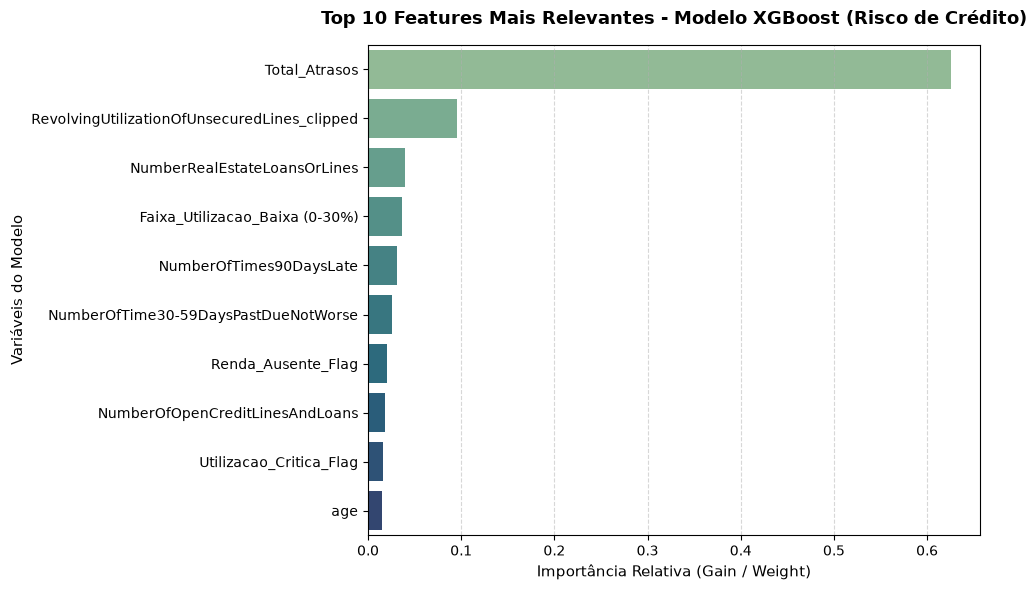

In [29]:
## Feature Importance

# Extraindo a importância das features do modelo XGBoost treinado
importance_features = pd.DataFrame({
    'Feature': X_train.columns,
    'Importancia': xgb_model.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Exibindo o Top 10 em tabela
print("Top 10 Variáveis Mais Importantes para o XGBoost:")
display(importance_features.head(10))

# Plotando o Gráfico de Importância das Features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_features.head(10),
    x='Importancia',
    y='Feature',
    palette='crest'
)

plt.title('Top 10 Features Mais Relevantes - Modelo XGBoost (Risco de Crédito)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Importância Relativa (Gain / Weight)', fontsize=11)
plt.ylabel('Variáveis do Modelo', fontsize=11)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# Salvando a imagem
import os
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "top10_features_importance_xgboost.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

**A Supremacia do Histórico de Atrasos (`Total_Atrasos`):** A variável criada na etapa de engenharia de recursos disparou na liderança isolada com mais de 62% de relevância, comprovando que o comportamento histórico de reincidência de atrasos é o maior indicador de risco de um tomador de crédito.

**Validação das Faixas de Utilização (`Faixa_Utilizacao`):** A presença destacada das faixas de utilização no ranking valida a importância das transformações que realizamos, mostrando que o uso do limite de crédito tem forte peso na predição do calote. 

O ranking demonstra que o XGBoost aprendeu os pilares fundamentais do crédito (comportamento passado + comprometimento do limite atual).

## Políticas de Crédito e Cut-offs

Um modelo de ML retorna apenas uma probabilidade bruta (ex: 0.15 de chance de inadimplência). O comitê de crédito de uma instituição financeira não toma decisões baseadas apenas em número cru, mas sim em políticas de corte (*cut-offs*) comerciais divididas por apetite ao risco:

* **Zona Verde (Aprovação Automática):** Clientes com baixíssima probabilidade de calote; ganham crédito imediato e taxas competitivas.

* **Zona Amarela (Alçada de Crédito / Análise Humana):** Risco moderado; o sistema encaminha para um analista humano ou exige garantias adicionais/taxas de juros mais altas para compensar o risco. 

* **Zona Vermelha (Recusa Automática):** Alto risco de inadimplência; o crédito é negado para proteger o capital da carteira. 

Relatório Executivo: Simulação de Política de Crédito por Cut-offs


,Segmento_Risco,Volume_Clientes,Porcentagem_Base (%),Taxa_Inadimplencia_Real (%)
0,1. Zona Verde (Aprovado Automaticamente),7147,23.82,0.49
1,2. Zona Amarela (Alçada / Análise Humana),10768,35.89,1.58
2,3. Zona Vermelha (Recusado Automaticamente),12085,40.28,14.89


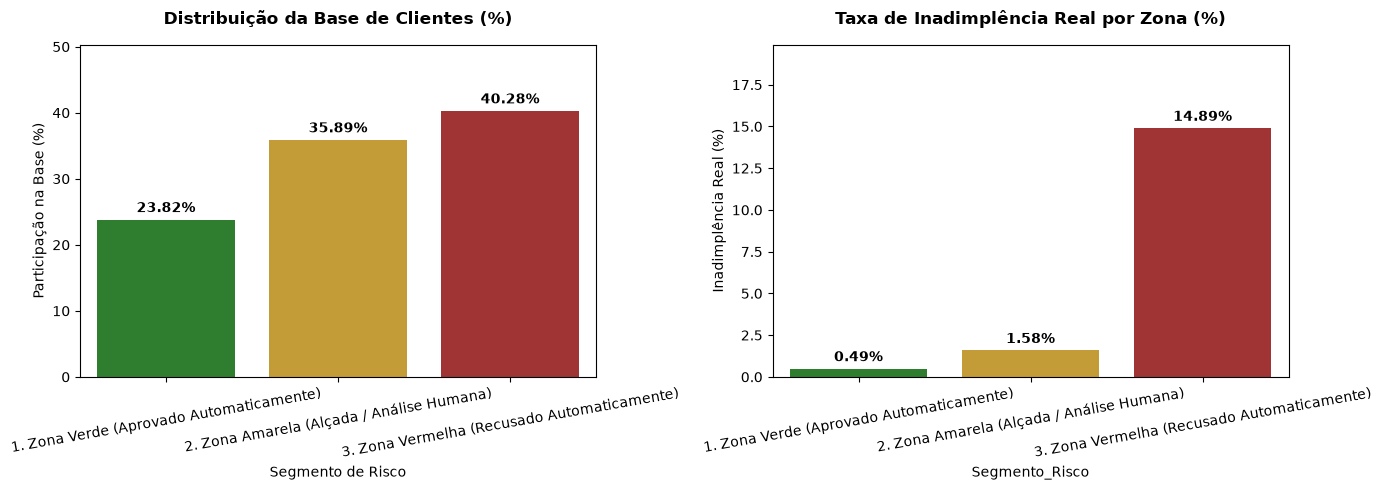

In [30]:
## Simulação de Política de Crédito e Faixas de Risco

# Criando um DataFrame auxiliar com as probabilidades do modelo campeão (XGBoost)
df_simulacao = pd.DataFrame({
    'y_true': y_test,
    'proba_default': y_pred_proba_xgb
})

# Definindo a função de política de crédito com base em cut-offs de probabilidade
def aplicar_politica_credito(proba):
    if proba < 0.10:
        return '1. Zona Verde (Aprovado Automaticamente)'
    elif proba < 0.30:
        return '2. Zona Amarela (Alçada / Análise Humana)'
    else:
        return '3. Zona Vermelha (Recusado Automaticamente)'

# Aplicando a política na base de teste
df_simulacao['Segmento_Risco'] = df_simulacao['proba_default'].apply(aplicar_politica_credito)

# Calculando métricas de negócio por zona de risco
resumo_politica = df_simulacao.groupby('Segmento_Risco').agg(
    Volume_Clientes=('y_true', 'count'),
    Taxa_Inadimplencia_Real=('y_true', 'mean')
).reset_index()

# Formatando as porcentagens para apresentação executiva
resumo_politica['Porcentagem_Base (%)'] = ((resumo_politica['Volume_Clientes'] / len(df_simulacao)) * 100).round(2)
resumo_politica['Taxa_Inadimplencia_Real (%)'] = (resumo_politica['Taxa_Inadimplencia_Real'] * 100).round(2)

# Reordenando e limpando colunas
resumo_politica = resumo_politica[['Segmento_Risco', 'Volume_Clientes', 'Porcentagem_Base (%)', 'Taxa_Inadimplencia_Real (%)']]

print("Relatório Executivo: Simulação de Política de Crédito por Cut-offs")
display(resumo_politica)

# Gráfico Executivo: Distribuição da Base e Taxa de Inadimplência por Zona de Risco
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Definindo cores institucionais/intuitivas para as zonas
cores_zonas = ['forestgreen', 'goldenrod', 'firebrick']

# Subplot 1: Porcentagem da Base por Zona de Risco
sns.barplot(
    data=resumo_politica,
    x='Segmento_Risco',
    y='Porcentagem_Base (%)',
    palette=cores_zonas,
    ax=axes[0],
    hue='Segmento_Risco',
    legend=False
)
axes[0].set_title('Distribuição da Base de Clientes (%)', fontsize=12, fontweight='bold', pad=15)
axes[0].set_xlabel('Segmento de Risco', fontsize=10)
axes[0].set_ylabel('Participação na Base (%)', fontsize=10)
axes[0].tick_params(axis='x', rotation=10)

# Adicionando os valores exatos nas barras do Subplot 1
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='black',
                xytext=(0, 3), textcoords='offset points')
axes[0].set_ylim(0, max(resumo_politica['Porcentagem_Base (%)']) + 10)

# Subplot 2: Taxa de Inadimplência Real por Zona de Risco
sns.barplot(
    data=resumo_politica,
    x='Segmento_Risco',
    y='Taxa_Inadimplencia_Real (%)',
    palette=cores_zonas,
    ax=axes[1],
    hue='Segmento_Risco',
    legend=False
)
axes[1].set_title('Taxa de Inadimplência Real por Zona (%)', fontsize=12, fontweight='bold', pad=15)
axes[1].set_xlabel('Segmento_Risco', fontsize=10)
axes[1].set_ylabel('Inadimplência Real (%)', fontsize=10)
axes[1].tick_params(axis='x', rotation=10)

# Adicionando os valores exatos nas barras do Subplot 2
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='black',
                xytext=(0, 3), textcoords='offset points')
axes[1].set_ylim(0, max(resumo_politica['Taxa_Inadimplencia_Real (%)']) + 5)

plt.tight_layout()

# Salvando a imagem
import os
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "politica_credito_cutoffs.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

**Separação de Risco:** A política de *cut-offs* provou ser extremamente eficaz. A **Zona Verde** apresenta uma inadimplência residual de apenas 0,49%, permitindo aprovação digital instantânea e segura. 

**Equilíbrio na Zona Amarela (1,58%):** A faixa intermediária (35,89% da base) captura clientes de risco moderado, ideais para alçada de crédito humana ou precificação baseada em risco (*risk-based pricing*).

**Blindagem de Capital na Zona Vermelha (14,89%):** O modelo barrou preventivamente os tomadores com alto risco de calote, protegendo a rentabilidade e a solvência da instituição financeira. 

---

## Resumo Executivo

**Conclusões do Projeto**:
 
* Performance Superior do Campeão: O modelo XGBoost estabeleceu-se como o campeão preditivo da carteira, entregando um ROC-AUC de 0.8694 e uma Estatística KS de 58,36%, superando o baseline regulatório de Regressão Logística.

* O Fator Comportamental: A engenharia de recursos revelou que o histórico acumulado de reincidência de atrasos (`Total_Atrasos`) responde por mais de 62% da importância preditiva do modelo, corroborando as teorias clássicas de risco de crédito.

* Eficiência de Negócio: A política de *cut-offs* estruturada permitiu aprovar instantaneamente a Zona Verde (23.82% da base com inadimplência residual de apenas 0.49%) e barrar preventivamente a Zona Vermelha (inadimplência de 14.89%), blindando o capital da instituição.

## Serialização dos Modelos *Regressão Logística* e *XGBoost*

Após treinar, validar e interpretar os modelos, o último passo do pipeline é serializar. Salvando o modelo em disco garantindo que ele possa ser carregado rapidamente para realizar predições em tempo real (como em uma API de concessão de crédito), sem a necessidade de reexecutar todo o treinamento.

In [31]:
## Serialização e Salvamento dos Modelos Treinados

import joblib

# Criando o diretório de modelos caso não exista
model_dir = os.path.join("..", "models")
os.makedirs(model_dir, exist_ok=True)

# Salvando o Pipeline da Regressão Logística (Baseline)
caminho_lr = os.path.join(model_dir, "baseline_regressao_logistica.pkl")
joblib.dump(pipeline_lr, caminho_lr)

# Salvando o Modelo Campeão (XGBoost)
caminho_xgb = os.path.join(model_dir, "xgboost.pkl")
joblib.dump(xgb_model, caminho_xgb)

print("Modelos salvos com sucesso na pasta '../models/'!")
print(f" - Baseline (LogReg): {caminho_lr}")
print(f" - Campeão (XGBoost): {caminho_xgb}")

Modelos salvos com sucesso na pasta '../models/'!
 - Baseline (LogReg): ..\models\baseline_regressao_logistica.pkl
 - Campeão (XGBoost): ..\models\xgboost.pkl
